In [1]:
import os, glob, zipfile, urllib.request, random
from collections import Counter

import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [2]:
SR = 44100
N_MELS = 128
N_MFCC = 40
MAX_LEN = 216
HOP = 512
N_FFT = 2048
EPOCHS = 25
BATCH = 16
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

device: cuda


In [3]:
zip_path = "./ESC-50-master.zip"
extracted_dir = "./ESC-50-master"

if not os.path.exists(extracted_dir):
    urllib.request.urlretrieve(
        "https://github.com/karolpiczak/ESC-50/archive/master.zip", zip_path
    )
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall("./")

df = pd.read_csv(os.path.join(extracted_dir, "meta", "esc50.csv"))
esc10_df = df[df["esc10"] == True].copy()

CLASSES = [
    "dog", "rain", "sea_waves", "crying_baby", "clock_tick",
    "sneezing", "helicopter", "chainsaw", "rooster", "crackling_fire",
]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

file_paths, labels = [], []
for _, row in esc10_df.iterrows():
    p = os.path.join(extracted_dir, "audio", row["filename"])
    if os.path.exists(p):
        file_paths.append(p)
        labels.append(CLASS_TO_IDX[row["category"]])

print(f"Файлов: {len(file_paths)}, классов: {len(CLASSES)}")

Файлов: 400, классов: 10


In [4]:
def load_and_center_audio(path, sr=SR, max_len_sec=5.0):
    y, _ = librosa.load(path, sr=sr, mono=True)
    y, _ = librosa.effects.trim(y, top_db=30)
    target_len = int(sr * max_len_sec)
    
    if len(y) < target_len:
        pad_total = target_len - len(y)
        pad_left = pad_total // 2
        pad_right = pad_total - pad_left
        y = np.pad(y, (pad_left, pad_right), mode="constant")
    else:
        start = (len(y) - target_len) // 2
        y = y[start:start+target_len]
        
    return y


def pad_or_crop(arr, max_len=MAX_LEN):
    if arr.shape[1] < max_len:
        pad = max_len - arr.shape[1]
        return np.pad(arr, ((0, 0), (0, pad)), mode="constant")
    return arr[:, :max_len]

In [5]:
def mel_spectrogram(y):
    mel = librosa.feature.melspectrogram(
        y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)
    return pad_or_crop(mel_db)


def mfcc_features(y):
    m = librosa.feature.mfcc(
        y=y, sr=SR, n_mfcc=N_MFCC, hop_length=HOP, n_fft=N_FFT
    )
    return pad_or_crop(m)


def logmel_with_deltas(y):
    mel = librosa.feature.melspectrogram(
        y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS
    )
    log_mel = librosa.power_to_db(mel, ref=np.max)
    d1 = librosa.feature.delta(log_mel, order=1)
    d2 = librosa.feature.delta(log_mel, order=2)
    stacked = np.vstack([log_mel, d1, d2])
    return pad_or_crop(stacked)


REPRESENTATIONS = {
    "mel":          mel_spectrogram,
    "mfcc":         mfcc_features,
    "logmel_delta": logmel_with_deltas,
}

/home/mlguest/miniforge3/envs/torch/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


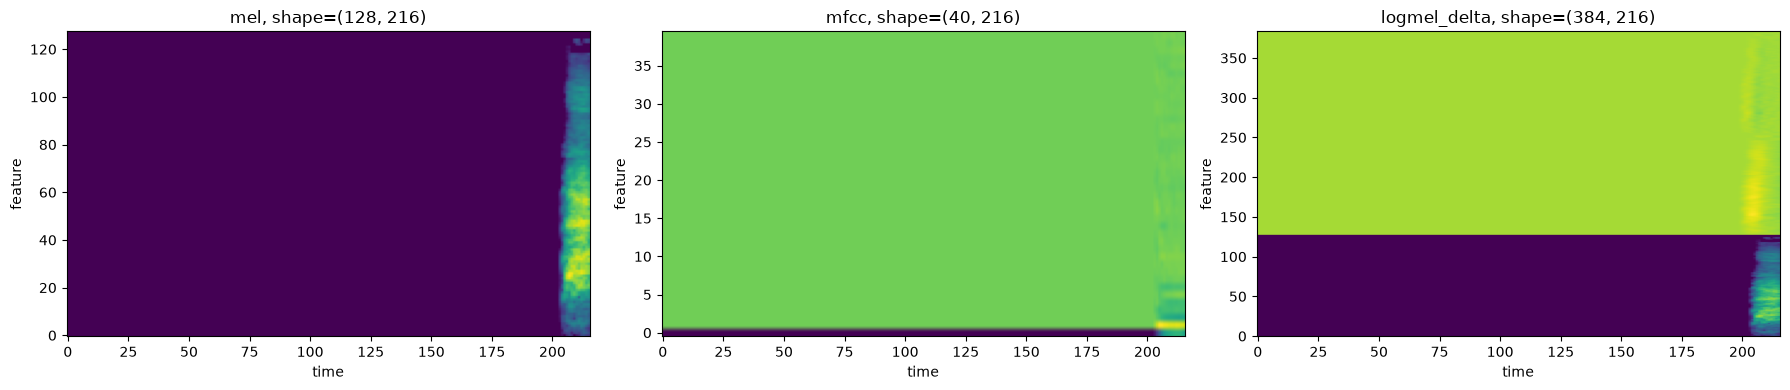

In [6]:
sample_y = load_and_center_audio(file_paths[0], sr=SR)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (name, fn) in zip(axes, REPRESENTATIONS.items()):
    spec = fn(sample_y) 
    
    ax.imshow(spec, aspect="auto", origin="lower", cmap="viridis")
    ax.set_title(f"{name}, shape={spec.shape}")
    ax.set_xlabel("time")
    ax.set_ylabel("feature")
    
plt.tight_layout()
plt.show()

In [7]:
import time

REPS_DATA = {name: [] for name in REPRESENTATIONS}
t0 = time.time()
for i, p in enumerate(file_paths):
    y, _ = librosa.load(p, sr=SR, mono=True)
    for name, fn in REPRESENTATIONS.items():
        REPS_DATA[name].append(fn(y))
    if (i + 1) % 100 == 0:
        print(f"  {i+1}/{len(file_paths)}  ({time.time()-t0:.1f} c)")

for name in REPS_DATA:
    REPS_DATA[name] = np.array(REPS_DATA[name])
    print(f"{name}: {REPS_DATA[name].shape}")

y_all = np.array(labels)

  100/400  (1.4 c)
  200/400  (2.9 c)
  300/400  (4.3 c)
  400/400  (5.7 c)
mel: (400, 128, 216)
mfcc: (400, 40, 216)
logmel_delta: (400, 384, 216)


In [8]:
def flatten_with_stats(rep):
    return np.concatenate([
        rep.mean(axis=2),
        rep.std(axis=2),
        rep.min(axis=2),
        rep.max(axis=2),
    ], axis=1)


def run_sklearn_models(rep_array, y, rep_name):
    X = flatten_with_stats(rep_array)
    X_tr, X_val, y_tr, y_val = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr)
    X_val_s = sc.transform(X_val)
    lr = LogisticRegression(max_iter=3000, C=1.0, n_jobs=-1)
    lr.fit(X_tr_s, y_tr)
    acc_lr = accuracy_score(y_val, lr.predict(X_val_s))

    rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)
    rf.fit(X_tr, y_tr)
    acc_rf = accuracy_score(y_val, rf.predict(X_val))

    print(f"  [{rep_name}] LR={acc_lr:.4f}  RF={acc_rf:.4f}  (X={X.shape})")
    return acc_lr, acc_rf

In [9]:
class SpectrogramCNN(nn.Module):
    def __init__(self, in_channels=1, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=(3, 7), padding=(1, 3)),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=(5, 3), padding=(2, 1)),
            nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=(5, 3), padding=(2, 1)),
            nn.BatchNorm2d(256), nn.ReLU(), nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(256, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


class RepDataset(Dataset):
    def __init__(self, reps, labels, augment=False):
        self.reps = reps
        self.labels = labels
        self.augment = augment

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        arr = self.reps[idx].copy()
        if self.augment:
            H, W = arr.shape
            for _ in range(2):
                w = random.randint(1, 20)
                t0 = random.randint(0, max(0, W - w))
                arr[:, t0:t0+w] = arr.min()
            for _ in range(2):
                w = random.randint(1, 16)
                f0 = random.randint(0, max(0, H - w))
                arr[f0:f0+w, :] = arr.min()
        x = torch.tensor(arr, dtype=torch.float32).unsqueeze(0)
        return x, torch.tensor(self.labels[idx], dtype=torch.long)


def run_cnn(rep_array, y, rep_name, epochs=EPOCHS):
    idx_tr, idx_val = train_test_split(
        np.arange(len(y)), test_size=0.2, random_state=42, stratify=y
    )
    tr = RepDataset(rep_array[idx_tr], y[idx_tr], augment=True)
    vl = RepDataset(rep_array[idx_val], y[idx_val], augment=False)
    tr_loader = DataLoader(tr, batch_size=BATCH, shuffle=True, num_workers=0)
    vl_loader = DataLoader(vl, batch_size=BATCH, shuffle=False, num_workers=0)
    model = SpectrogramCNN(in_channels=1, n_classes=len(CLASSES)).to(DEVICE)
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    opt = optim.Adam(model.parameters(), lr=1e-3)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    best = 0.0
    for ep in range(epochs):
        model.train()
        for x, yy in tr_loader:
            x, yy = x.to(DEVICE), yy.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(x), yy)
            loss.backward()
            opt.step()
        sch.step()

        model.eval()
        correct = total = 0
        with torch.no_grad():
            for x, yy in vl_loader:
                x, yy = x.to(DEVICE), yy.to(DEVICE)
                correct += (model(x).argmax(1) == yy).sum().item()
                total += yy.size(0)
        acc = correct / total
        best = max(best, acc)

    print(f"  [{rep_name}] CNN best={best:.4f}")
    return best

In [10]:
results = []

for rep_name, rep_array in REPS_DATA.items():
    print(f"\n=== {rep_name}  shape={rep_array.shape} ===")
    acc_lr, acc_rf = run_sklearn_models(rep_array, y_all, rep_name)
    acc_cnn = run_cnn(rep_array, y_all, rep_name)
    results.append({
        "representation": rep_name,
        "shape": f"{rep_array.shape[1]}×{rep_array.shape[2]}",
        "LR": acc_lr,
        "RF": acc_rf,
        "CNN": acc_cnn,
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


=== mel  shape=(400, 128, 216) ===


/home/mlguest/miniforge3/envs/torch/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  [mel] LR=0.8000  RF=0.7250  (X=(400, 512))
  [mel] CNN best=0.9125

=== mfcc  shape=(400, 40, 216) ===


/home/mlguest/miniforge3/envs/torch/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  [mfcc] LR=0.7625  RF=0.8500  (X=(400, 160))
  [mfcc] CNN best=0.5375

=== logmel_delta  shape=(400, 384, 216) ===


/home/mlguest/miniforge3/envs/torch/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  [logmel_delta] LR=0.8750  RF=0.8250  (X=(400, 1536))
  [logmel_delta] CNN best=0.8250
representation   shape     LR    RF    CNN
           mel 128×216 0.8000 0.725 0.9125
          mfcc  40×216 0.7625 0.850 0.5375
  logmel_delta 384×216 0.8750 0.825 0.8250



Accuracy по представлениям и моделям:
                    LR     RF     CNN
representation                       
mel             0.8000  0.725  0.9125
mfcc            0.7625  0.850  0.5375
logmel_delta    0.8750  0.825  0.8250

Лучшая комбинация: mel + CNN = 0.9125


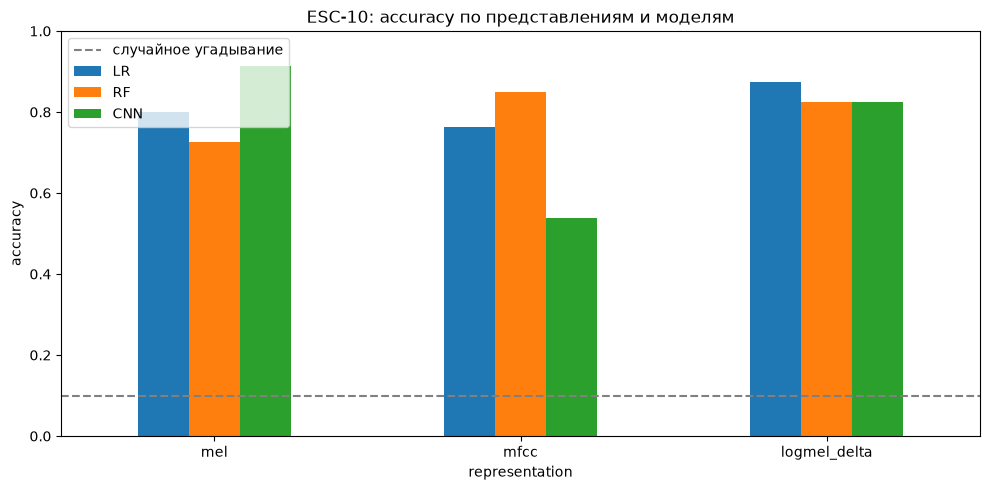

In [11]:
pivot = results_df.set_index("representation")[["LR", "RF", "CNN"]]
print("\nAccuracy по представлениям и моделям:")
print(pivot.round(4).to_string())

best_row = pivot.stack().idxmax()
best_val = pivot.stack().max()
print(f"\nЛучшая комбинация: {best_row[0]} + {best_row[1]} = {best_val:.4f}")

pivot.plot(kind="bar", figsize=(10, 5), rot=0)
plt.title("ESC-10: accuracy по представлениям и моделям")
plt.ylabel("accuracy")
plt.ylim(0, 1)
plt.axhline(0.1, color="gray", linestyle="--", label="случайное угадывание")
plt.legend()
plt.tight_layout()
plt.show()